# Time interpolation and extrapolation with reduced-order models

In this example, we compare three reduced-order modeling strategies for a time-dependent PDE at a fixed value of the Péclet number $Pe$.

The three approaches are:

- **POD-RBF:** a non-intrusive ROM that interpolates the POD coefficients using radial basis functions.
- **POD-NN:** a non-intrusive ROM that learns the POD coefficients using an artificial neural network.
- **POD-DEIM:** an intrusive ROM that evolves the reduced coefficients by integrating the projected equations, with the nonlinear term approximated using the discrete empirical interpolation method (DEIM).

The objective is to investigate how accurately these methods reproduce the FOM solution both within the time interval used for training and beyond it.

We define a training horizon $T_{\mathrm{train}}$ and a final evaluation time $T_{\mathrm{end}}$. The ROMs are trained using snapshots from the interval

$
0\leq t\leq T_{\mathrm{train}},
$

and evaluated at selected times up to $T_{\mathrm{end}}$.

This setup allows us to distinguish two tasks:

1. **Time interpolation:** predicting the solution at times inside the training interval that were not used to train the model.
2. **Time extrapolation:** predicting the solution at times beyond the training interval, where no FOM snapshots were provided to the regression models during training.

The same FOM trajectory provides the reference solution for both assessments.

In [ ]:
# %%
import glob
import os
import time
import warnings
import numpy as np
import scipy.sparse as sp
import scipy.linalg as la
import matplotlib.pyplot as plt

from scipy.interpolate import RBFInterpolator
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

T_train = 0.4
T_end = 0.5
dt = 1e-6
HOLDOUT_EVERY = 5
energy_target = 0.999
N_SNAPSHOTS = 900

FILES = {
    100: "./snapshots/trajectory_40.npz",
    1000: "./snapshots/trajectory_80.npz",
}

M = sp.load_npz("M.npz").toarray()
K = sp.load_npz("K.npz").toarray()
C = sp.load_npz("C.npz").toarray()

In [141]:
# %%
def load_trajectory(filename):
    with np.load(filename) as d:
        keys = list(d.keys())
        key = next((k for k in ("S", "snapshots", "U", "u")
                    if k in keys), None)
        if key is None:
            raise KeyError(f"No snapshot matrix in {filename}: {keys}")

        S = np.asarray(d[key], dtype=float)
        t = np.asarray(
            d["t"] if "t" in keys else
            d["time"] if "time" in keys else
            np.linspace(0, T_end, S.shape[1]), dtype=float
        ).ravel()
        x = np.asarray(d["x"]).ravel() if "x" in keys else np.arange(S.shape[0])

    if S.shape[1] != len(t):
        if S.shape[0] == len(t):
            S = S.T
        else:
            raise ValueError(f"Inconsistent shapes: S={S.shape}, t={t.shape}")

    if len(x) != S.shape[0]:
        x = np.arange(S.shape[0])

    idx = np.argsort(t)
    return S[:, idx], t[idx], x


def subsample(S, t, n):
    idx = np.unique(np.linspace(0, len(t) - 1, min(n, len(t))).astype(int))
    return S[:, idx], t[idx]


data = {}

for Pe, filename in FILES.items():
    if not os.path.exists(filename):
        candidates = glob.glob("./snapshots/*.npz")
        raise FileNotFoundError(
            f"Snapshot file not found: {filename}\n"
            f"Available files: {[os.path.basename(f) for f in candidates]}"
        )

    S, t, x = load_trajectory(filename)

    if t[0] > 1e-12 or t[-1] < T_end - 1e-10:
        raise ValueError(
            f"Pe={Pe}: trajectory spans [{t[0]}, {t[-1]}], "
            f"but [0, {T_end}] is required."
        )

    data[Pe] = {"S": S, "t": t, "x": x}
    print(f"Pe={Pe}: S shape={S.shape}, time interval=[{t[0]}, {t[-1]}]")

Pe=100: S shape=(999, 1001), time interval=[0.0, 0.5]
Pe=1000: S shape=(999, 1001), time interval=[0.0, 0.5]


## 1. Settings and data

We first define the temporal intervals, numerical time step, snapshot selection strategy, and target POD energy.

The available trajectory is divided into two regions:

- **Training interval:** $t\in[0,T_{\mathrm{train}}]$. Snapshots from this interval are used to construct the POD basis and train the non-intrusive models.
- **Evaluation interval:** $t\in[0,T_{\mathrm{end}}]$. Selected snapshots within the training interval are withheld for interpolation testing, while all snapshots after $T_{\mathrm{train}}$ are used to assess extrapolation.

To evaluate interpolation independently of the training data, every `HOLDOUT_EVERY`-th snapshot in the training interval is withheld, excluding the endpoints. The number of training snapshots can also be capped to control computational cost.

The mass, stiffness, and convection matrices, $M$, $K$, and $C$, are loaded from the finite element discretization.

The same temporal partitioning strategy is applied to both values of $Pe$.

In [142]:
# %%
for Pe, d in data.items():
    S, t = d["S"], d["t"]

    pre_idx = np.flatnonzero(t <= T_train + 1e-12)
    local = np.arange(len(pre_idx))
    test_local = (local % HOLDOUT_EVERY == 0)
    test_local[0] = False
    test_local[-1] = False

    train_idx = pre_idx[~test_local]
    interp_idx = pre_idx[test_local]
    extra_idx = np.flatnonzero(t > T_train + 1e-12)
    eval_idx = np.sort(np.concatenate((interp_idx, extra_idx)))

    S_train, t_train = subsample(S[:, train_idx], t[train_idx], N_SNAPSHOTS)

    d.update({
        "S_train": S_train,
        "t_train": t_train,
        "S_test": S[:, eval_idx],
        "t_test": t[eval_idx],
        "interp": t[eval_idx] < T_train,
        "extra": t[eval_idx] > T_train,
    })

    print(
        f"Pe={Pe}: {len(t_train)} training snapshots, "
        f"{d['interp'].sum()} interpolation tests, "
        f"{d['extra'].sum()} extrapolation tests"
    )

Pe=100: 762 training snapshots, 39 interpolation tests, 200 extrapolation tests
Pe=1000: 762 training snapshots, 39 interpolation tests, 200 extrapolation tests


In [143]:
# %%
def pod(S):
    eig, V = la.eigh(S.T @ M @ S)
    idx = np.argsort(eig)[::-1]
    eig, V = eig[idx], V[:, idx]

    keep = eig > max(eig[0], 0.0) * 1e-14
    eig, V = eig[keep], V[:, keep]

    if len(eig) == 0:
        raise ValueError("Snapshot matrix has zero energy.")

    cumulative = np.cumsum(eig) / eig.sum()
    N = np.searchsorted(cumulative, energy_target) + 1
    Z = S @ (V[:, :N] / np.sqrt(eig[:N]))

    return Z, N, cumulative[N - 1]


for Pe, d in data.items():
    Z, N, energy = pod(d["S_train"])
    d.update({
        "Z": Z,
        "N": N,
        "energy": energy,
        "A_train": Z.T @ M @ d["S_train"],
    })

    print(f"Pe={Pe}: N={N}, cumulative energy={energy:.8f}")

Pe=100: N=5, cumulative energy=0.99921912
Pe=1000: N=17, cumulative energy=0.99924191


In [144]:
# %%
def fit_rbf(t_train, A_train, t_eval):
    start = time.perf_counter()

    model = RBFInterpolator(
        t_train[:, None], A_train.T,
        kernel="thin_plate_spline",
        smoothing=1e-10,
    )
    A_pred = model(t_eval[:, None]).T

    return A_pred, time.perf_counter() - start


def fit_nn(t_train, A_train, t_eval):
    sx, sy = StandardScaler(), StandardScaler()
    X = sx.fit_transform(t_train[:, None])
    Y = sy.fit_transform(A_train.T)

    model = MLPRegressor(
        hidden_layer_sizes=(64, 64),
        activation="tanh",
        max_iter=5000,
        tol=1e-8,
        random_state=1,
        verbose=True,
    )

    start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X, Y)

    A_pred = sy.inverse_transform(
        model.predict(sx.transform(t_eval[:, None]))
    ).T

    return A_pred, time.perf_counter() - start


def fit_gpr(t_train, A_train, t_eval):
    sx, sy = StandardScaler(), StandardScaler()
    X = sx.fit_transform(t_train[:, None])
    Y = sy.fit_transform(A_train.T)

    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * RBF(1.0, (1e-2, 1e2))
        + WhiteKernel(1e-6, (1e-10, 1e-1))
    )
    model = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=False,
        n_restarts_optimizer=0,
    )

    start = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X, Y)

    A_pred = sy.inverse_transform(
        model.predict(sx.transform(t_eval[:, None]))
    ).T

    return A_pred, time.perf_counter() - start

In [ ]:
# %%
for Pe, d in data.items():
    Z = d["Z"]
    t_train, t_test = d["t_train"], d["t_test"]
    A_train = d["A_train"]

    A_rbf, time_rbf = fit_rbf(t_train, A_train, t_test)
    A_nn, time_nn = fit_nn(t_train, A_train, t_test)
    A_gpr, time_gpr = fit_gpr(t_train, A_train, t_test)

    d.update({
        "RBF": Z @ A_rbf,
        "NN": Z @ A_nn,
        "GPR": Z @ A_gpr,
        "times": {
            "POD-RBF": time_rbf,
            "POD-NN": time_nn,
            "POD-GPR": time_gpr,
        },
    })

Iteration 1, loss = 0.64358382
Iteration 2, loss = 0.49921374
Iteration 3, loss = 0.40675951
Iteration 4, loss = 0.35449884
Iteration 5, loss = 0.32956161
Iteration 6, loss = 0.32203289
Iteration 7, loss = 0.32249181
Iteration 8, loss = 0.32302668
Iteration 9, loss = 0.32224754
Iteration 10, loss = 0.31966704
Iteration 11, loss = 0.31684669
Iteration 12, loss = 0.31495797
Iteration 13, loss = 0.31373909
Iteration 14, loss = 0.31289588
Iteration 15, loss = 0.31243734
Iteration 16, loss = 0.31149738
Iteration 17, loss = 0.31053617
Iteration 18, loss = 0.30971784
Iteration 19, loss = 0.30862414
Iteration 20, loss = 0.30755833
Iteration 21, loss = 0.30657261
Iteration 22, loss = 0.30557956
Iteration 23, loss = 0.30440082
Iteration 24, loss = 0.30298163
Iteration 25, loss = 0.30153999
Iteration 26, loss = 0.30003993
Iteration 27, loss = 0.29855838
Iteration 28, loss = 0.29695138
Iteration 29, loss = 0.29499825
Iteration 30, loss = 0.29305055
Iteration 31, loss = 0.29114630
Iteration 32, los

In [ ]:
# ------------------------------------------------------------
# DEIM: offline stage
# ------------------------------------------------------------
def deim_offline(S_train):
    F = C @ S_train**2
    U, s, _ = la.svd(F, full_matrices=False)
    if len(s) == 0 or s[0] == 0:
        raise ValueError("Nonlinear snapshots have zero energy.")
    rank = np.count_nonzero(s > s[0] * 1e-12)
    return U[:, :rank]


# ------------------------------------------------------------
# DEIM: interpolation points
# ------------------------------------------------------------
def deim_points(U):
    m = U.shape[1]
    p = np.empty(m, dtype=int)
    p[0] = np.argmax(np.abs(U[:, 0]))

    for k in range(1, m):
        coeff = la.solve(U[p[:k], :k], U[p[:k], k])
        residual = U[:, k] - U[:, :k] @ coeff
        p[k] = np.argmax(np.abs(residual))

    return p


# ------------------------------------------------------------
# DEIM: reduced-model setup
# ------------------------------------------------------------
def deim_setup(Z, G, p):
    m = G.shape[1]
    B = Z.T @ G @ la.solve(G[p, :], np.eye(m))

    C_P = C[p, :]
    cols = np.flatnonzero(np.any(C_P != 0, axis=0))   
    C_P = C_P[:, cols]                                 
    Z_S = Z[cols, :]                                  
    K_N = Z.T @ K @ Z
    return B, C_P, Z_S, K_N

# ------------------------------------------------------------
# DEIM: online integration
# ------------------------------------------------------------
def rom_deim(Z, S0, Pe, G, p, t0, t_eval):
    B, C_P, Z_S, K_N = deim_setup(Z, G, p)

    a = Z.T @ M @ S0
    steps = np.rint((t_eval - t0) / dt).astype(int)
    target_map = {int(s): j for j, s in enumerate(steps)}
    out = np.empty((Z.shape[0], len(t_eval)))

    start = time.perf_counter()
    for n in range(int(steps[-1]) + 1):
        if n in target_map:
            out[:, target_map[n]] = Z @ a
        if n == steps[-1]:
            break

        u_S = Z_S @ a
        f_S = C_P @ (u_S**2)
        a -= dt * (K_N @ a / Pe + B @ f_S)

    return out, time.perf_counter() - start

In [ ]:
# %%
for Pe, d in data.items():
    start = time.perf_counter()
    G = deim_offline(d["S_train"])
    m = min(4 * d["N"], G.shape[1])
    G = G[:, :m]
    p = deim_points(G)
    deim_offline_time = time.perf_counter() - start

    U_deim, online_time = rom_deim(
        d["Z"], d["S"][:, 0], Pe,
        G, p, d["t"][0], d["t_test"],
    )

    d["DEIM"] = U_deim
    d["m"] = m
    d["times"]["DEIM offline"] = deim_offline_time
    d["times"]["DEIM online"] = online_time

    print(
        f"Pe={Pe}: m={m}, "
        f"DEIM offline={deim_offline_time:.3f} s, "
        f"online={online_time:.3f} s"
    )

Pe=100: m=20, DEIM offline=0.242 s, online=3.678 s
Pe=1000: m=68, DEIM offline=0.163 s, online=4.406 s


In [ ]:
# %%
def err_M(U, Uref):
    E = U - Uref
    return np.sqrt(np.maximum(np.sum(E * (M @ E), axis=0), 0.0))


for Pe, d in data.items():
    S_test = d["S_test"]

    d["errors"] = {
        f"POD-{name}": err_M(d[name], S_test)
        for name in ("RBF", "NN", "GPR", "DEIM")
    }

    print(f"\nPe={Pe}")
    print(f"  Training snapshots: {len(d['t_train'])}")
    print(f"  Interpolation test snapshots: {d['interp'].sum()}")
    print(f"  Extrapolation test snapshots: {d['extra'].sum()}")
    print(f"  POD modes N={d['N']}, cumulative energy={d['energy']:.8f}")
    print(f"  DEIM modes m={d['m']}")

    for name, e in d["errors"].items():
        print(
            f"  {name:8s}: "
            f"interpolation mean={np.mean(e[d['interp']]):.6e}, "
            f"extrapolation mean={np.mean(e[d['extra']]):.6e}"
        )

    for name, elapsed in d["times"].items():
        print(f"  {name:8s} time: {elapsed:.3f} s")


Pe=100
  Training snapshots: 722
  Interpolation test snapshots: 79
  Extrapolation test snapshots: 200
  POD modes N=5, cumulative energy=0.99921873
  DEIM modes m=20
  POD-RBF : interpolation mean=8.960891e-04, extrapolation mean=1.336991e-02
  POD-NN  : interpolation mean=9.892390e-04, extrapolation mean=2.411786e-03
  POD-GPR : interpolation mean=8.960890e-04, extrapolation mean=1.524482e-02
  POD-DEIM: interpolation mean=1.080144e-03, extrapolation mean=2.595169e-03
  POD-RBF  time: 0.012 s
  POD-NN   time: 1.967 s
  POD-GPR  time: 10.703 s
  DEIM offline time: 0.242 s
  DEIM online time: 3.678 s

Pe=1000
  Training snapshots: 722
  Interpolation test snapshots: 79
  Extrapolation test snapshots: 200
  POD modes N=17, cumulative energy=0.99923828
  DEIM modes m=68
  POD-RBF : interpolation mean=1.434796e-03, extrapolation mean=1.467489e-02
  POD-NN  : interpolation mean=2.119473e-03, extrapolation mean=1.346369e-02
  POD-GPR : interpolation mean=1.434791e-03, extrapolation mean=3

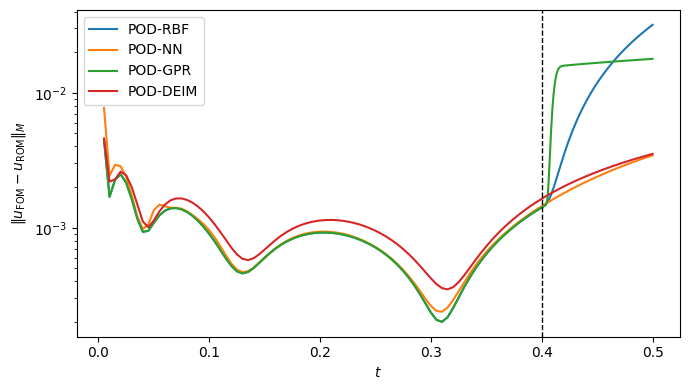

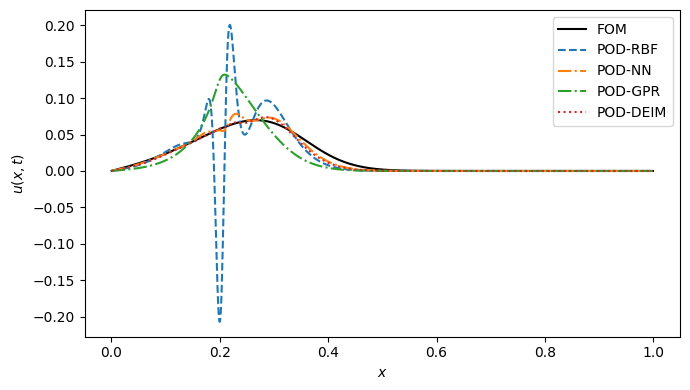

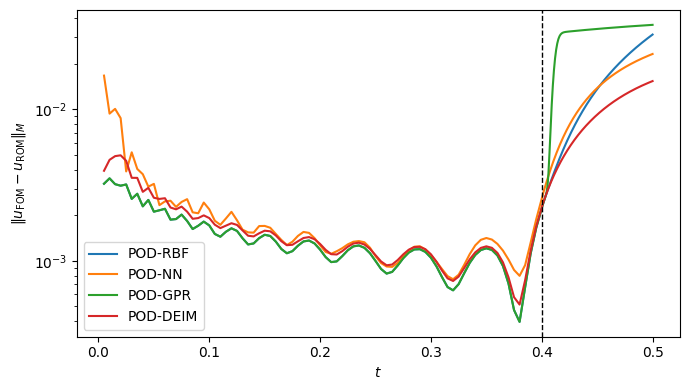

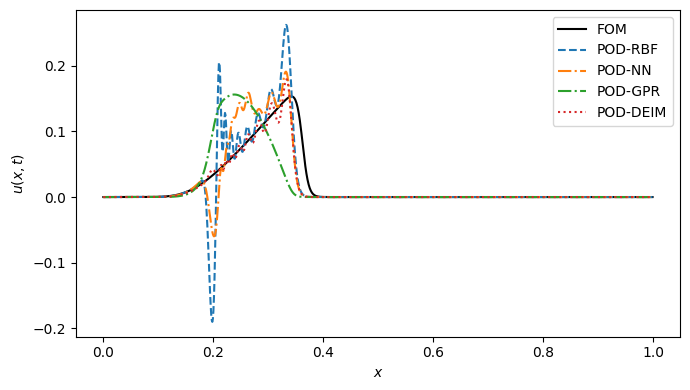

In [ ]:
# %%
for Pe, d in data.items():
    fig, ax = plt.subplots(figsize=(7, 4))

    for name, e in d["errors"].items():
        ax.semilogy(d["t_test"], e, label=name)

    ax.axvline(T_train, color="k", linestyle="--", linewidth=1)
    ax.set_xlabel(r"$t$")
    ax.set_ylabel(r"$\|u_{\mathrm{FOM}}-u_{\mathrm{ROM}}\|_M$")
    ax.legend()
    fig.tight_layout()

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(d["x"], d["S_test"][:, -1], "k-", label="FOM")
    ax.plot(d["x"], d["RBF"][:, -1], "--", label="POD-RBF")
    ax.plot(d["x"], d["NN"][:, -1], "-.", label="POD-NN")
    ax.plot(d["x"], d["GPR"][:, -1], "-.", label="POD-GPR")
    ax.plot(d["x"], d["DEIM"][:, -1], ":", label="POD-DEIM")
    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$u(x,t)$")
    ax.legend()
    fig.tight_layout()

plt.show()


## Physical diagnostics: energy law and maximum principle

The FOM is a finite-element discretization of the viscous Burgers equation, $u_t + u u_x = \tfrac{1}{Pe}u_{xx}$ with homogeneous Dirichlet conditions. Besides the $M$-norm error against the FOM, a ROM should respect the main structural properties of the equation. We check them on the extrapolation window $t>T_{\mathrm{train}}$, where regression-based models receive no data.

**Energy law.** Let $E(t)=\tfrac12\,\mathbf u^\top M\mathbf u=\tfrac12\|\mathbf u\|_M^2$. For the semi-discrete system,

$$
\dot E=-\tfrac{1}{Pe}\,\mathbf u^\top K\mathbf u-\mathbf u^\top C(\mathbf u^2).
$$

The viscous term is always dissipative, because $K$ is symmetric positive definite. In the continuous problem the convective term is energy-neutral, so $E$ decreases monotonically. In the discrete FOM this holds only approximately, since $\mathbf u^\top C(\mathbf u^2)=\tfrac12\sum_i u_iu_{i+1}(u_{i+1}-u_i)\neq0$ in general. It is a consistency error that is expected to be small.

**Maximum principle.** The exact solution satisfies $0\le u\le\max u_0$, and the maximum does not grow. The discretization does not enforce this, but small violations in the FOM are a useful baseline.

**What is computed** (for FOM, POD projection, DEIM-ROM, POD-RBF, POD-NN and POD-GPR):

- `E up [%]`: percentage of time steps where $E$ increases. It should be 0 for the FOM.
- `E_end/E_ref`: final energy relative to the FOM energy at the start of the extrapolation window. Flat or collapsing energy signals wrong physics.
- `defect/E_ref`: maximum of $\left|E(t)-E(t_0)-\int_{t_0}^t\dot E\,ds\right|/E_{\mathrm{ref}}$, with $\dot E$ given by the formula above. It measures how far a trajectory is from satisfying the energy law. The FOM gives the noise floor from time sampling.
- `min u`, `max u`: checks of the maximum principle.

**How to read the results.**

- The regression models (RBF, NN, GPR) are not constrained by the equation, so their defect is expected to grow with the extrapolation horizon.
- The DEIM-ROM is a Galerkin projection with an oblique hyper-reduction of the nonlinear term. A defect much larger than that of the POD projection means the energy structure of the FOM has been lost.
- The POD projection gives the reference: it is the best $M$-orthogonal approximation of the FOM in the reduced space.
- Because the basis is $M$-orthonormal, $\tfrac12\|\mathbf a\|_2^2=E_r$. The energy of a ROM can therefore be read directly from its reduced coefficients.


Pe = 100, extrapolation window t > 0.4
method           E up [%]  E_end/E_ref  defect/E_ref     min u    max u
FOM                   0.0       0.8924       9.9e-09   1.7e-19   0.0779
POD projection        0.0       0.8834       6.4e-02   1.6e-20   0.0780
DEIM-ROM              0.0       0.8571       4.1e-04   1.4e-20   0.0789
POD-RBF              81.9       1.9196       1.1e+01  -2.1e-01   0.2005
POD-NN                0.0       0.9351       1.1e-01   1.6e-20   0.0788
POD-GPR              31.7       1.4981       1.0e+00   4.1e-21   0.1322

Pe = 1000, extrapolation window t > 0.4
method           E up [%]  E_end/E_ref  defect/E_ref     min u    max u
FOM                   0.0       0.8964       1.4e-06  3.7e-180   0.1712
POD projection        0.0       0.7836       6.6e-02  1.0e-181   0.1969
DEIM-ROM              0.0       0.7490       5.3e-04  1.1e-181   0.1906
POD-RBF              94.0       1.4715       1.5e+00  -1.9e-01   0.2627
POD-NN              100.0       1.2066       4.7e-01  -

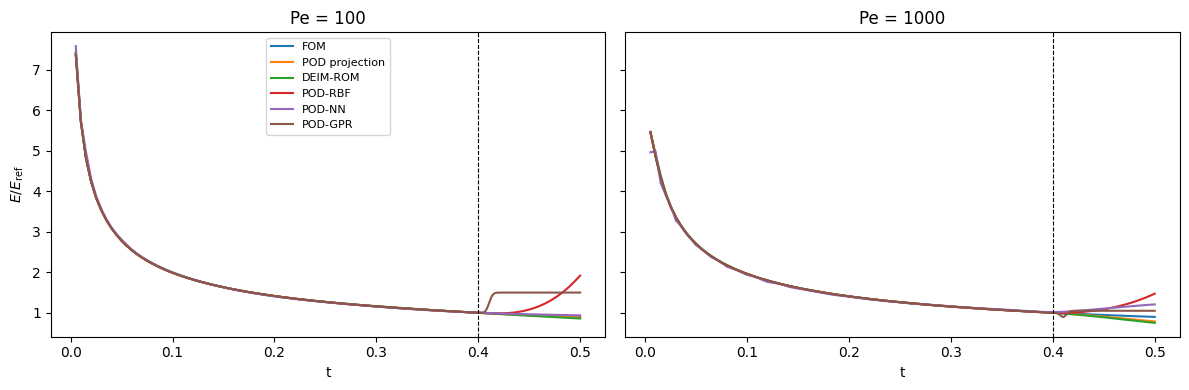

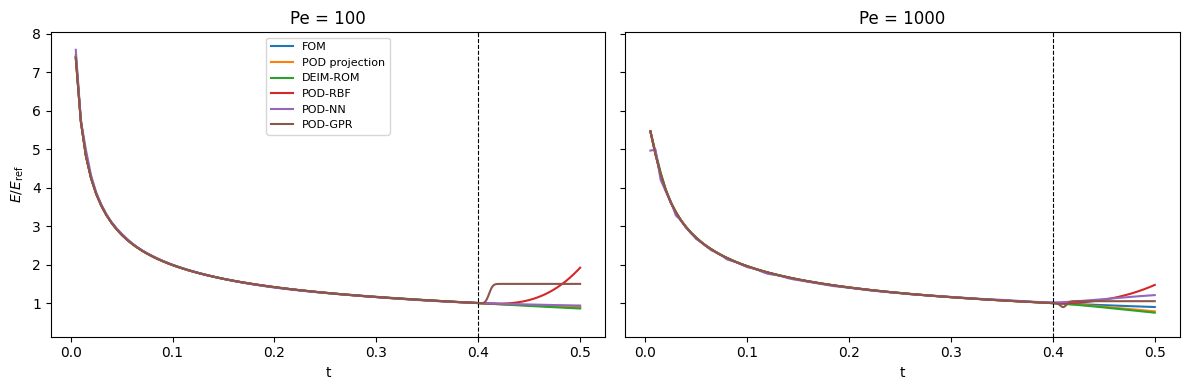

In [ ]:
# =====================================================================
# PHYSICAL DIAGNOSTICS (energy law and maximum principle)
# =====================================================================
from scipy.integrate import cumulative_trapezoid

LABELS = {"DEIM": "DEIM-ROM", "RBF": "POD-RBF", "NN": "POD-NN", "GPR": "POD-GPR"}


def energy(U):
    return 0.5 * np.einsum("ij,ij->j", U, M @ U)


def energy_defect(U, t, Pe):
    """E(t) - E(t0) - int dE/dt, with dE/dt = -u'Ku/Pe - u'C(u^2) (0 if u solves the FOM)."""
    E = energy(U)
    rate = np.einsum("ij,ij->j", U, K @ U) / Pe + np.einsum("ij,ij->j", U, C @ U**2)
    return E - E[0] + cumulative_trapezoid(rate, t, initial=0.0)


rows, E_curves = {}, {}
for Pe, d in data.items():
    ext, t_all = d["extra"], d["t_test"]
    models = {"FOM": d["S_test"], "POD projection": d["Z"] @ (d["Z"].T @ M @ d["S_test"])}
    models.update({LABELS[k]: d[k] for k in LABELS if k in d})

    with np.errstate(all="ignore"):
        E_curves[Pe] = {n: energy(U) for n, U in models.items()}
        E_ref = energy(d["S_test"][:, ext])[0]
        rows[Pe] = {}
        for n, U in models.items():
            Ue, E = U[:, ext], E_curves[Pe][n][ext]
            rows[Pe][n] = (
                100 * np.mean(np.diff(E) > 1e-12 * E_ref),                  # % steps with E increasing
                E[-1] / E_ref,                                              # final energy vs FOM start
                np.max(np.abs(energy_defect(Ue, t_all[ext], Pe))) / E_ref,  # energy-law defect
                Ue.min(), Ue.max(),
            )
        E_curves[Pe]["_ref"] = E_ref

for Pe, r in rows.items():
    print(f"\nPe = {Pe}, extrapolation window t > {T_train}")
    print(f"{'method':<16}{'E up [%]':>9}{'E_end/E_ref':>13}{'defect/E_ref':>14}{'min u':>10}{'max u':>9}")
    for n, v in r.items():
        print(f"{n:<16}{v[0]:9.1f}{v[1]:13.4f}{v[2]:14.1e}{v[3]:10.1e}{v[4]:9.4f}")

fig, axs = plt.subplots(1, len(data), figsize=(6 * len(data), 4), sharey=True)
for ax, (Pe, c) in zip(np.atleast_1d(axs), E_curves.items()):
    for n, E in c.items():
        if n != "_ref":
            ax.plot(data[Pe]["t_test"], E / c["_ref"], label=n)
    ax.axvline(T_train, color="k", lw=0.8, ls="--")
    ax.set(title=f"Pe = {Pe}", xlabel="t")
np.atleast_1d(axs)[0].set_ylabel(r"$E/E_{\rm ref}$")
np.atleast_1d(axs)[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

proj = np.concatenate([c["POD projection"] / c["_ref"] for c in E_curves.values()])
lo, hi = proj.min(), proj.max()
pad = 0.1 * (hi - lo)

fig, axs = plt.subplots(1, len(data), figsize=(6 * len(data), 4), sharey=True)
axs = np.atleast_1d(axs)
for ax, (Pe, c) in zip(axs, E_curves.items()):
    for n, E in c.items():
        if n != "_ref":
            ax.plot(data[Pe]["t_test"], E / c["_ref"], label=n)
    ax.axvline(T_train, color="k", lw=0.8, ls="--")
    ax.set(title=f"Pe = {Pe}", xlabel="t", ylim=(lo - pad, hi + pad))
axs[0].set_ylabel(r"$E/E_{\rm ref}$")
axs[0].legend(fontsize=8)
fig.tight_layout()
plt.show()